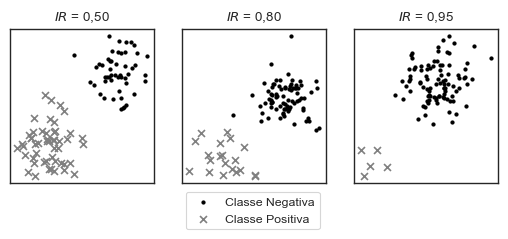

In [46]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

matplotlib.use("pgf")
# matplotlib.use('macOsX')
matplotlib.rcParams.update({
    'axes.formatter.use_locale': True,
    "pgf.texsystem": "pdflatex",
    # 'font.family': 'serif',
    # 'text.usetex': True,
    # 'pgf.rcfonts': False,
})
%matplotlib inline

sns.set_style('white')
sns.set_context("paper", font_scale = 1)

# Set the random seed for reproducibility
np.random.seed(42)


# Create three datasets with varying levels of imbalance
def create_dataset(n_samples, imbalance_ratio):
    n_majority = int(n_samples * imbalance_ratio)
    n_minority = n_samples - n_majority
    
    # Majority class (centered around (2,2))
    x_majority = np.random.randn(n_majority, 2) + np.array([2, 2])
    
    # Minority class (centered around (-2,-2))
    x_minority = np.random.randn(n_minority, 2) + np.array([-2, -2])
    
    # Combine the datasets
    X = np.vstack((x_majority, x_minority))
    y = np.hstack((np.zeros(n_majority), np.ones(n_minority)))
    
    return X, y

# Define the number of samples and imbalance ratios
n_samples = 100
ratios = [0.5, 0.8, 0.95]  # Balanced, moderately imbalanced, highly imbalanced

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(6.29707, 2))

# Generate and plot each dataset
for i, ratio in enumerate(ratios):
    X, y = create_dataset(n_samples, ratio)
    axes[i].scatter(X[y == 0][:, 0], X[y == 0][:, 1], s=5, color='black', label='Classe Negativa')
    axes[i].scatter(X[y == 1][:, 0], X[y == 1][:, 1], s=25, color='grey', marker='x', label='Classe Positiva')
    razao = f'{ratio:.2f}'.replace('.', ',')
    axes[i].set_title(f'$IR$ = {razao}')
    if i == 2:
        axes[i].legend(bbox_to_anchor=(-0.2, -0.02))
    axes[i].get_xaxis().set_visible(False)
    axes[i].get_yaxis().set_visible(False)
# Display the plots
plt.savefig(
    f'ir_examples.png',
    bbox_inches="tight"
)
plt.show()